In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)
print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
cancer=load_breast_cancer()

In [8]:
X=pd.DataFrame(cancer.data,columns=cancer.feature_names)
y=pd.Series(cancer.target,name='target')
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [9]:
print("first 5 rows:")
display(X.head())
print("Dataset shape:",X.shape)
print("\nTarget values:")
print(y.value_counts())

first 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Dataset shape: (569, 30)

Target values:
target
1    357
0    212
Name: count, dtype: int64


In [12]:
print("Missing values in each column:")
print(X.isnull().sum())
print("\ntotal missing values:",X.isnull().sum().sum())

Missing values in each column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
dtype: int64

total missing values: 0


In [13]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)


Training data: (455, 30)
Testing data: (114, 30)


In [14]:
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Training data standardized:",X_train_scaled.shape)
print("Testing data standardized:",X_test_scaled.shape)

Training data standardized: (455, 30)
Testing data standardized: (114, 30)


In [16]:
model=LogisticRegression(max_iter=1000)
model.fit(X_train_scaled,y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [17]:
y_pred=model.predict(X_test_scaled)
print("first 10 predictions:")
print(y_pred[:10])

first 10 predictions:
[0 1 0 1 0 1 1 0 0 0]


Confusion Matrix:
[[41  1]
 [ 1 71]]


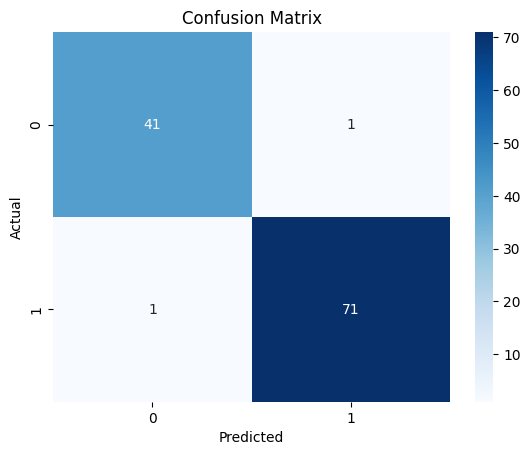

In [18]:
cm=confusion_matrix(y_test,y_pred)
print("Confusion Matrix:")
print(cm)

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [19]:
precision=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred)

print("Precision:",precision)
print("Recall:",recall)

Precision: 0.9861111111111112
Recall: 0.9861111111111112


In [20]:
y_prob=model.predict_proba(X_test_scaled)[:,1]
roc_auc=roc_auc_score(y_test,y_prob)
print("ROC-AUC Score :",roc_auc)

ROC-AUC Score : 0.9953703703703703


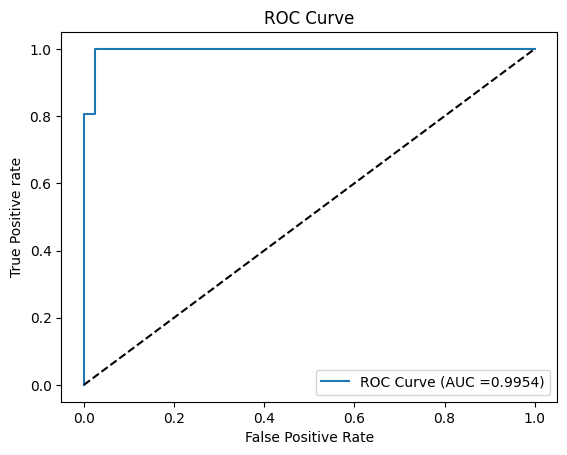

In [21]:
fpr,tpr,tresholds=roc_curve(y_test,y_prob)
plt.plot(fpr,tpr,label=f'ROC Curve (AUC ={roc_auc:.4f})')
plt.plot([0,1],[0,1],'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


### Sigmoid Function

The sigmoid function is used in Logistic Regression to convert model outputs into probabilities between 0 and 1.

It is represented as:

σ(z) = 1 / (1 + e⁻ᶻ)

A threshold of 0.5 is commonly used to classify the output into two classes.

- Probability ≥ 0.5: Class 1 (Benign)
- Probability < 0.5: Class 0 (Malignant)

In [22]:
y_prob =model.predict_proba(X_test_scaled)[:,1]
threshold=0.6
y_pred_new=(y_prob>=threshold).astype(int)
print("New Threshold:",threshold)
print("New Confusion Matrix:")
print(confusion_matrix(y_test,y_pred_new))
print("New Precision:",precision_score(y_test,y_pred_new))
print("New Recall:",recall_score(y_test,y_pred_new))

New Threshold: 0.6
New Confusion Matrix:
[[41  1]
 [ 4 68]]
New Precision: 0.9855072463768116
New Recall: 0.9444444444444444


### Threshold Tuning Conclusion

The default classification threshold was 0.5. We also tested a threshold of 0.6.

At threshold 0.5, the recall was 98.61%.

At threshold 0.6, the recall decreased to 94.44%.

This shows that increasing the classification threshold changes the model's predictions and affects precision and recall.

Threshold selection is important because it depends on the requirements of the classification problem.

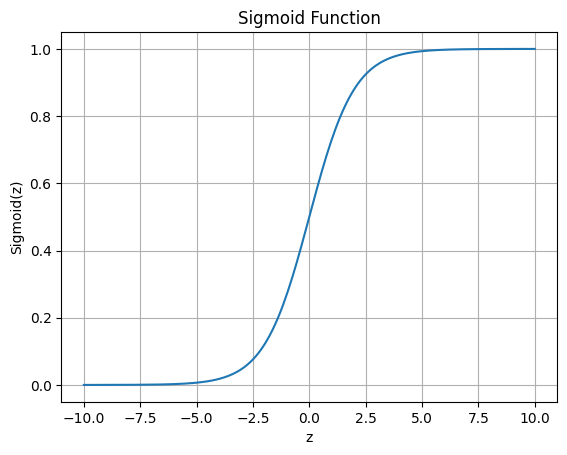

In [23]:
z=np.linspace(-10,10,200)
sigmoid=1/(1+np.exp(-z))

plt.plot(z,sigmoid)
plt.xlabel("z")
plt.ylabel("Sigmoid(z)")
plt.title("Sigmoid Function")
plt.grid(True)
plt.show()

### Conclusion

In this task, I implemented Logistic Regression using the Breast Cancer Wisconsin dataset.

I performed the following steps:

1. Loaded and explored the dataset.
2. Checked for missing values.
3. Split the data into training and testing sets.
4. Standardized the features.
5. Trained a Logistic Regression model.
6. Evaluated the model using a confusion matrix, precision, recall, and ROC-AUC score.
7. Plotted the ROC curve and sigmoid function.
8. Tested a different classification threshold.

The model achieved an ROC-AUC score of approximately 0.9954, indicating excellent ability to distinguish between the two classes on the test data.

This task helped me understand binary classification, Logistic Regression, the sigmoid function, and model evaluation metrics.